# Prioritising epitopes in one antigen, end to end

The decision this notebook walks through: **given NY-ESO-1 and a four-allele HLA panel, which peptides do we synthesise first?**

NY-ESO-1 (CTAG1B, UniProt [P78358](https://rest.uniprot.org/uniprotkb/P78358.fasta)) is a cancer-testis antigen with a well-described immunodominant HLA-A\*02:01 epitope at residues 157–165, `SLLMWITQC`. That known answer makes it a useful yardstick - not because a good pipeline must put `SLLMWITQC` on top (it does not; see step 3), but because knowing the answer is what lets you see *how* a ranking reorders the frames around it. Read on for the good test case: a pipeline that cannot find it is broken.

Switch `PREDICTOR` to `"mhcflurry"` if you have installed the extra and fetched its models. With `"toy"` the numbers are a deterministic placeholder — fine for following the mechanics, not for making decisions.

In [1]:
from pathlib import Path

from epitope_rank.fasta import read_fasta
from epitope_rank.predictors import get_predictor
from epitope_rank.ranking import RankingConfig, rank_peptides
from epitope_rank.tiling import tile

PREDICTOR = "mhcflurry"  # or "toy" for an offline run with placeholder numbers
ALLELES = ["HLA-A*02:01", "HLA-A*01:01", "HLA-B*07:02", "HLA-B*08:01"]
FASTA = Path("..") / "data" / "NY-ESO-1_P78358.fasta"

antigen = read_fasta(FASTA)[0]
print(antigen.name)
print(f"{len(antigen)} aa")
print(f"residues 157-165: {antigen.sequence[156:165]}")

sp|P78358|CTG1B_HUMAN Cancer/testis antigen 1 OS=Homo sapiens OX=9606 GN=CTAG1A PE=1 SV=1
180 aa
residues 157-165: SLLMWITQC


## 1. Tile

Every 9mer and 10mer, each carrying its 1-based start position so a hit can be traced back to the antigen.

In [2]:
peptides = tile(antigen.sequence, lengths=[9, 10], protein="NY-ESO-1")
print(f"{len(peptides)} peptides")
for p in peptides[:3]:
    print(f"  {p.start:>3}-{p.end:<3} {p.sequence}")

343 peptides
    1-9   MQAEGRGTG
    1-10  MQAEGRGTGG
    2-10  QAEGRGTGG


## 2. Score and rank

Each distinct peptide is scored once per allele, then collapsed to one row per position: its best allele, and how many alleles in the panel bind it.

Breadth leads the sort. A peptide binding all four alleles covers more of the patient population per peptide made, and synthesis is the budget.

In [3]:
predictor = get_predictor(PREDICTOR)
shortlist, all_scores = rank_peptides(
    peptides, ALLELES, predictor, RankingConfig(top_n=10)
)

print(f"{len(all_scores)} peptide x allele pairs scored")
print(f"{int(all_scores['is_binder'].sum())} pairs cleared both cutoffs\n")
shortlist[["rank", "peptide", "start", "best_allele", "best_percentile", "n_alleles_bound"]]

1372 peptide x allele pairs scored
51 pairs cleared both cutoffs



,rank,peptide,start,best_allele,best_percentile,n_alleles_bound
0,1,AADHRQLQL,139,HLA-B*08:01,0.614,3
1,2,APRGPHGGAA,60,HLA-B*07:02,0.007,2
2,3,APRGPHGGA,60,HLA-B*07:02,0.014,2
3,4,GPHGGAASGL,63,HLA-B*07:02,0.046,2
4,5,APPLPVPGVL,113,HLA-B*07:02,0.092,2
5,6,APPLPVPGV,113,HLA-B*07:02,0.301,2
6,7,LAMPFATPM,92,HLA-B*07:02,0.528,2
7,8,EAELARRSL,101,HLA-B*08:01,0.584,2
8,9,GPGGGAPRGP,55,HLA-B*07:02,0.777,2
9,10,LLMWITQCFL,158,HLA-A*02:01,0.057,1


## 3. Where did the known epitope land?

Not on the shortlist, as it happens - and that is the instructive part rather than a bug.
`SLLMWITQC` binds only HLA-A\*02:01, so breadth-first ranking demotes it. What *does* appear
is an overlapping frame. The question worth asking of a shortlist is therefore whether it
covers the **region**, not whether it contains one particular 9mer.


In [4]:
KNOWN_START, KNOWN_END = 157, 165

overlapping = shortlist[
    (shortlist["start"] <= KNOWN_END) & (shortlist["end"] >= KNOWN_START)
]
print(f"{len(overlapping)} of {len(shortlist)} shortlisted peptides overlap SLLMWITQC (157-165)")
overlapping[["rank", "peptide", "start", "end", "n_alleles_bound"]]

1 of 10 shortlisted peptides overlap SLLMWITQC (157-165)


,rank,peptide,start,end,n_alleles_bound
9,10,LLMWITQCFL,158,167,1


## 4. Explain a rejection

`all_scores` is kept so that "why isn't this peptide on the list?" has an answer with numbers in it. Here is the worst-scoring peptide and what each allele did with it.

In [5]:
worst = all_scores.sort_values("percentile", ascending=False).iloc[0]["peptide"]
print(f"rejected: {worst}")
all_scores[all_scores["peptide"] == worst][
    ["peptide", "allele", "affinity_nm", "percentile", "is_binder"]
]

rejected: ARRSLAQDA


,peptide,allele,affinity_nm,percentile,is_binder
208,ARRSLAQDA,HLA-A*02:01,22219.0,33.299,False
551,ARRSLAQDA,HLA-A*01:01,37937.0,99.265,False
894,ARRSLAQDA,HLA-B*07:02,27068.9,28.600,False
1237,ARRSLAQDA,HLA-B*08:01,24205.8,15.365,False


## 5. Look at the whole antigen

Strong binders at the top, shortlist circled, position on the x axis. The useful question of this plot is whether hits cluster into a region worth tiling more finely, or scatter.

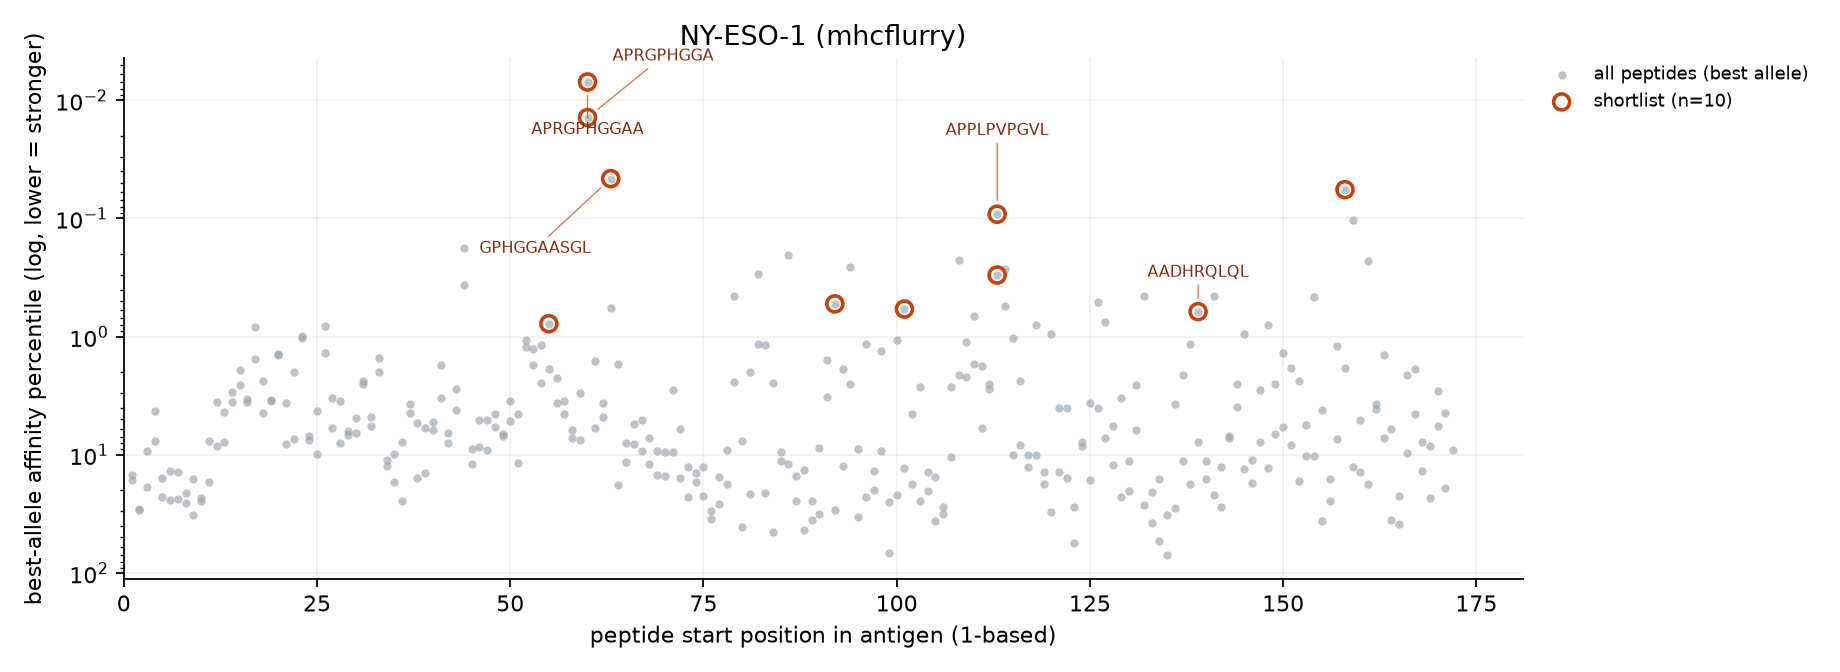

In [6]:
from IPython.display import Image

from epitope_rank.plotting import plot_landscape

png = plot_landscape(
    all_scores,
    shortlist,
    "nb-output/landscape.png",
    protein_length=len(antigen),
    title=f"NY-ESO-1 ({predictor.name})",
)
Image(filename=str(png))

## What this does not tell you

Predicted binding is one necessary condition out of several. Processing, transport, the available T-cell repertoire and tolerance all sit between a tight binder and an actual response, and none of them are modelled here. The next steps a real campaign would add: filter candidates against the human proteome for cross-reactivity, weight breadth by allele frequency in the population being treated, and send the shortlist out for synthesis and an immunogenicity readout — which is the point where this list stops being a prediction and starts being data.